### **Student Information**
GitHub ID:

Kaggle name:

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

---

## 1. Model Development (10 pts Required)

### 1.1 Preprocessing Steps

**Data Integration**

The original dataset contained 4,800 social media posts, including 3,360 training samples and 1,440 testing samples. The raw posts, emotion labels, and dataset identification files were merged using `post_id` as the unique identifier.

The classification task involved six emotion categories: anger, disgust, fear, joy, sadness, and surprise.

**Text Normalization**

The following preprocessing techniques were applied:

- HTML decoding to restore encoded characters.
- Unicode NFKC normalization to standardize character representations.
- Lowercasing to reduce unnecessary vocabulary variation.
- Replacement of URLs and user mentions with special tokens.
- Whitespace normalization to remove redundant spaces.
- Standardization of quotation marks.

Punctuation, negation words, and emojis were preserved because they may provide important emotional information. Stop-word removal and stemming were not applied because these operations might remove useful contextual information.

**Duplicate and Conflicting Label Handling**

After text normalization, 16 unique texts were found to have conflicting emotion labels. All 32 observations associated with these conflicting texts were removed to reduce contradictory supervision.

Additionally, 34 duplicate training observations were removed to reduce the influence of repeated samples.

| Item | Number of Samples |
|---|---:|
| Original training samples | 3,360 |
| Removed conflicting observations | 32 |
| Removed duplicate observations | 34 |
| Total removed observations | 66 |
| Final training samples | 3,294 |
| Final testing samples | 1,440 |

Approximately 1.96% of the original training observations were removed. All testing samples were preserved.

**Class Distribution and Data Quality**

The class distribution after preprocessing was:

| Emotion | Training Samples |
|---|---:|
| Joy | 870 |
| Anger | 656 |
| Sadness | 614 |
| Disgust | 441 |
| Surprise | 436 |
| Fear | 277 |
| Total | 3,294 |

![Training Class Distribution](./pics/homework_class_distribution.png)

*Figure 1. Class distribution of the 3,294 training samples after preprocessing.*

The dataset was moderately imbalanced, with approximately 3.14 times as many joy samples as fear samples. Therefore, Macro F1 was selected as the primary model evaluation metric, and balanced class weights were considered during hyperparameter tuning.

There were also 59 unique overlapping texts between the training and testing datasets. The original dataset split was preserved, and no testing labels were used during model development. However, this overlap remains a potential limitation of the dataset.

---

### 1.2 Feature Engineering Steps

Three TF-IDF feature representations were investigated: word-level TF-IDF, character-level TF-IDF, and combined TF-IDF.

**Word-level TF-IDF**

Word-level TF-IDF was used as the baseline feature representation. Both unigrams and bigrams were included to capture individual words and short contextual phrases.

The main parameter settings were:

- N-gram range: (1, 2)
- Minimum document frequency: 2
- Maximum document frequency: 0.95
- Maximum number of features: 30,000
- Sublinear term frequency: True
- Normalization: L2

The resulting vocabulary contained 7,554 features, including 2,947 unigrams and 4,607 bigrams.

**Character-level TF-IDF**

Character-level TF-IDF was introduced to capture subword patterns, spelling variations, punctuation, and informal expressions commonly found in social media posts.

The main parameter settings were:

- N-gram range: (2, 5)
- Minimum document frequency: 2
- Maximum document frequency: 0.95
- Maximum number of features: 50,000
- Sublinear term frequency: True
- Normalization: L2

The resulting vocabulary contained 48,637 character-level features.

Unlike word-level TF-IDF, character-level TF-IDF produced nonzero feature vectors for every training and testing document.

**Combined TF-IDF**

Word-level and character-level TF-IDF features were concatenated to investigate whether the two representations provided complementary information.

Both feature representations were assigned equal weights.

**Feature Comparison**

| Feature Representation | Number of Features | Sparsity | Zero-feature Training Documents | Zero-feature Testing Documents |
|---|---:|---:|---:|---:|
| Word TF-IDF | 7,554 | 99.75% | 3 | 3 |
| Character TF-IDF | 48,637 | 99.48% | 0 | 0 |
| Combined TF-IDF | 56,191 | 99.52% | 0 | 0 |

![Feature Representation Comparison](./pics/homework_feature_comparison.png)

*Figure 2. Number of features generated by the three TF-IDF representations.*

Although all three feature matrices were highly sparse, sparse matrix representations allowed efficient storage and computation.

During cross-validation, TF-IDF vectorizers were included inside classification pipelines and fitted separately within each training fold. This prevented validation documents from influencing vocabulary construction and IDF estimation.

---

### 1.3 Explanation of Your Model

**Model Selection**

Linear Support Vector Machine (Linear SVM) was selected because it is suitable for high-dimensional and sparse text classification problems.

Compared with more complex models, Linear SVM provides computational efficiency and explicit regularization, making it a reasonable choice for a relatively small training dataset.

The initial experiments used:

- Classifier: LinearSVC
- Regularization parameter C: 1.0
- Class weight: None
- Random state: 42
- Maximum iterations: 10,000

**Evaluation Strategy**

Stratified five-fold cross-validation was used to evaluate model performance while maintaining approximately the same class proportions in each fold.

Three evaluation metrics were considered:

- Accuracy
- Macro F1
- Weighted F1

Macro F1 was selected as the primary evaluation metric because it assigns equal importance to each emotion category, regardless of its sample size.

**Feature Representation Comparison**

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| Word TF-IDF + Linear SVM | 0.4809 | 0.4584 | 0.4750 |
| Character TF-IDF + Linear SVM | 0.5219 | 0.4997 | 0.5150 |
| Combined TF-IDF + Linear SVM | 0.5121 | 0.4924 | 0.5071 |

Character-level TF-IDF achieved the highest validation performance among the three initial models.

Compared with word-level TF-IDF, character-level TF-IDF improved Macro F1 by 4.13 percentage points. This improvement may be attributed to its ability to capture subword patterns and informal expressions.

Combining word-level and character-level features did not further improve performance. Additional features may have introduced redundant information or noise. Differences in feature scaling may also have affected the effective regularization strength.

**Hyperparameter Tuning**

Since character-level TF-IDF achieved the best initial performance, GridSearchCV was applied to optimize its Linear SVM classifier.

The following hyperparameters were investigated:

- C: 0.01, 0.1, 0.5, 1.0, 2.0, and 5.0
- Class weight: None and balanced

A total of 12 parameter combinations were evaluated using stratified five-fold cross-validation, resulting in 60 cross-validation model fits.

| C | Class Weight | Validation Macro F1 |
|---:|---|---:|
| 0.01 | None | 0.1106 |
| 0.01 | Balanced | 0.4480 |
| 0.10 | None | 0.4522 |
| 0.10 | Balanced | 0.4941 |
| 0.50 | None | 0.5006 |
| 0.50 | Balanced | **0.5039** |
| 1.00 | None | 0.4997 |
| 1.00 | Balanced | 0.5023 |
| 2.00 | None | 0.4969 |
| 2.00 | Balanced | 0.4977 |
| 5.00 | None | 0.4913 |
| 5.00 | Balanced | 0.4922 |

![Hyperparameter Tuning Results](./pics/homework_hyperparameter_tuning.png)

*Figure 3. Validation Macro F1 across different regularization parameters and class weight settings. Error bars represent the standard deviation across five cross-validation folds.*

The best parameter combination was C = 0.5 and class_weight = balanced.

Smaller values of C impose stronger regularization, while larger values place greater emphasis on minimizing training errors. Balanced class weights increase the importance of minority classes during model training.

**Final Model Comparison**

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| Word TF-IDF + Linear SVM | 0.4809 | 0.4584 | 0.4750 |
| Combined TF-IDF + Linear SVM | 0.5121 | 0.4924 | 0.5071 |
| Character TF-IDF + Linear SVM | 0.5219 | 0.4997 | 0.5150 |
| Tuned Character TF-IDF + Linear SVM | **0.5219** | **0.5039** | **0.5195** |

![Final Model Performance Comparison](./pics/homework_model_comparison.png)

*Figure 4. Five-fold cross-validation performance of the four evaluated classification models.*

The tuned model improved Macro F1 by approximately 4.55 percentage points compared with the word-level baseline.

**Final Model Configuration**

| Parameter | Setting |
|---|---|
| Feature representation | Character-level TF-IDF |
| N-gram range | (2, 5) |
| Minimum document frequency | 2 |
| Maximum document frequency | 0.95 |
| Maximum features | 50,000 |
| Classifier | Linear SVM |
| C | 0.5 |
| Class weight | Balanced |
| Cross-validation | Stratified 5-fold |
| Random state | 42 |

**Final Prediction**

The selected model was refitted using all 3,294 preprocessed training observations and used to predict the emotion labels of 1,440 testing observations.

The prediction distribution was:

| Emotion | Predicted Count | Percentage |
|---|---:|---:|
| Joy | 407 | 28.26% |
| Anger | 321 | 22.29% |
| Sadness | 268 | 18.61% |
| Surprise | 182 | 12.64% |
| Disgust | 153 | 10.62% |
| Fear | 109 | 7.57% |
| Total | 1,440 | 100% |

A local `submission.csv` file was generated with two columns: `post_id` and `label`.

All submission integrity checks passed, including sample size, unique identifiers, prediction labels, missing values, and consistency with the official sample submission order.

**Limitations**

Although the tuned model achieved the best validation Macro F1 of 0.5039, its training Macro F1 was 0.9964, indicating substantial overfitting.

Furthermore, the same cross-validation procedure was used for model selection and hyperparameter tuning. Therefore, the reported best validation score may be optimistically biased.

Only the character-level representation was further tuned, so the selected model is the best among the evaluated configurations rather than a guaranteed global optimum.

Finally, the Kaggle competition deadline had already passed when the local model was completed. Therefore, the generated submission file was not officially submitted, and no Kaggle leaderboard score or ranking was obtained.

---

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

ChatGPT was used as a learning assistant during model development. Its suggestions were evaluated through local experiments rather than accepted solely based on AI-generated explanations.

The following summarizes the main AI-assisted discussions and the corresponding methodological decisions.

**1. Data Preprocessing**

Discussion topic:

How to preprocess social media text for emotion classification while preserving useful emotional information.

AI suggestions:

- Apply minimal text normalization.
- Replace URLs and user mentions with special tokens.
- Preserve punctuation, emojis, and negation words.
- Investigate duplicate texts and conflicting labels.

Decision and reason:

Minimal preprocessing was adopted because punctuation and informal expressions may contain important emotional signals. Aggressive preprocessing, such as stop-word removal and stemming, was not adopted because it might remove useful information.

Conflicting training observations and repeated texts were removed to reduce contradictory supervision and repeated observations.

However, removing conflicting labels may also discard genuinely ambiguous emotional expressions.

**2. Feature Engineering**

Discussion topic:

How to represent short and informal social media texts using TF-IDF.

AI suggestions:

- Use word-level unigrams and bigrams as a baseline.
- Investigate character-level n-grams.
- Combine word-level and character-level representations.

Decision and reason:

All three representations were implemented and evaluated using the same cross-validation strategy.

Character-level TF-IDF was selected because its validation Macro F1 of 0.4997 exceeded both the word-level baseline of 0.4584 and the combined representation of 0.4924.

The combined representation was not selected because it did not provide additional validation improvement.

**3. Model Selection and Evaluation**

Discussion topic:

Which classifier and evaluation strategy are suitable for high-dimensional, sparse, and imbalanced text classification.

AI suggestions:

- Use Linear SVM for sparse TF-IDF features.
- Apply stratified five-fold cross-validation.
- Use Macro F1 as the primary evaluation metric.
- Fit TF-IDF vectorizers within classification pipelines.

Decision and reason:

These suggestions were adopted because Linear SVM is suitable for sparse text representations, while stratified cross-validation maintains approximately consistent class proportions.

Macro F1 was selected to evaluate minority and majority emotion categories equally.

Classification pipelines were used to prevent validation data from influencing feature extraction.

**4. Hyperparameter Tuning**

Discussion topic:

How to reduce overfitting and improve classification performance on an imbalanced dataset.

AI suggestions:

- Investigate different regularization parameters C.
- Compare unweighted and balanced class weights.
- Use GridSearchCV to evaluate parameter combinations.

Decision and reason:

These suggestions were adopted because the initial models achieved nearly perfect training performance but substantially lower validation performance.

The experimental results showed that C = 0.5 and balanced class weights achieved the highest validation Macro F1 of 0.5039.

Although the improvement was relatively small, the selected configuration performed better than the initial character-level baseline.

**5. Final Prediction and Validation**

Discussion topic:

How to generate predictions in the required Kaggle submission format.

AI suggestions:

- Predict labels using the selected model.
- Match predictions with the official sample submission using post_id.
- Check the number of observations, missing values, valid labels, and identifier order.

Decision and reason:

These suggestions were adopted to ensure that the generated submission file followed the required format.

All integrity checks were performed locally, and the final submission file contained 1,440 predictions without missing values.

**Reflection on AI Assistance**

AI assistance helped organize the experimental workflow, explain methodological choices, and identify potential implementation problems.

However, the final model was selected based on actual cross-validation results rather than AI recommendations alone. For example, combined TF-IDF was investigated but not selected because it performed worse than character-level TF-IDF.

The reported numerical results were obtained from locally executed experiments. AI-generated explanations were treated as possible interpretations rather than verified causal explanations of model performance.

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
### Add the code related to the preprocessing steps in cells inside this section

import pandas as pd
import numpy as np
import json
from pathlib import Path

DATA_DIR = Path("data/competition")

# Load CSV files
identification = pd.read_csv(DATA_DIR / "data_identification.csv")
emotion = pd.read_csv(DATA_DIR / "emotion.csv")
sample_submission = pd.read_csv(DATA_DIR / "sampleSubmission.csv")

# Load raw JSON data
with open(DATA_DIR / "final_posts.json", encoding="utf-8") as f:
    raw_posts = json.load(f)

# Inspect CSV datasets
for name, df in [
    ("Identification", identification),
    ("Emotion", emotion),
    ("Sample Submission", sample_submission)
]:
    print(f"\n=== {name} ===")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())

# Inspect JSON structure
print("\n=== Raw Posts ===")
print("Data type:", type(raw_posts).__name__)
print("Length:", len(raw_posts))

if isinstance(raw_posts, list) and raw_posts:
    print("First record:", str(raw_posts[0])[:2000])
elif isinstance(raw_posts, dict) and raw_posts:
    first_key = next(iter(raw_posts))
    print("First key:", first_key)
    print("First value:", str(raw_posts[first_key])[:2000])


=== Identification ===
Shape: (4800, 2)
Columns: ['post_id', 'set']


,post_id,set
0,f8bv5zh,train
1,q0rr1l9,train
2,p94rwgk,train
3,9u6wtvm,train
4,h8ea329,train



=== Emotion ===
Shape: (3360, 2)
Columns: ['post_id', 'label']


,post_id,label
0,f8bv5zh,disgust
1,q0rr1l9,disgust
2,p94rwgk,sadness
3,9u6wtvm,fear
4,h8ea329,fear



=== Sample Submission ===
Shape: (1440, 2)
Columns: ['post_id', 'label']


,post_id,label
0,xyzx9jp,sadness
1,l3vzzxt,sadness
2,g680iug,sadness
3,m4t8bp6,sadness
4,ai3al6e,sadness



=== Raw Posts ===
Data type: list
Length: 4800
First record: {'post_id': 'f8bv5zh', 'text': 'Thought it looked weird as well.'}


In [2]:
# Convert JSON records into a DataFrame
posts = pd.DataFrame(raw_posts)

# Check unique identifiers
assert identification["post_id"].is_unique
assert posts["post_id"].is_unique
assert emotion["post_id"].is_unique
assert sample_submission["post_id"].is_unique

# Merge post text and emotion labels
df = identification.merge(
    posts,
    on="post_id",
    how="left",
    validate="one_to_one"
)

df = df.merge(
    emotion,
    on="post_id",
    how="left",
    validate="one_to_one"
)

# Split data according to the official dataset assignment
train_df = df[df["set"] == "train"].copy()
test_df = df[df["set"] == "test"].copy()

# Validate dataset integrity
assert len(train_df) == 3360
assert len(test_df) == 1440
assert train_df["label"].notna().all()
assert test_df["label"].isna().all()
assert set(test_df["post_id"]) == set(sample_submission["post_id"])

# Inspect merged datasets
print("Merged dataset shape:", df.shape)
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\n=== Missing Values ===")
print(df.isna().sum())

print("\n=== Training Label Distribution ===")
print(train_df["label"].value_counts())

print("\n=== Training Examples ===")
display(train_df.head())

print("\n=== Testing Examples ===")
display(test_df.head())

Merged dataset shape: (4800, 4)
Training dataset shape: (3360, 4)
Testing dataset shape: (1440, 4)

=== Missing Values ===
post_id       0
set           0
text          0
label      1440
dtype: int64

=== Training Label Distribution ===
label
joy         875
anger       674
sadness     628
disgust     454
surprise    441
fear        288
Name: count, dtype: int64

=== Training Examples ===


,post_id,set,text,label
0,f8bv5zh,train,Thought it looked weird as well.,disgust
1,q0rr1l9,train,Bear died in a pit,disgust
2,p94rwgk,train,I have endured worse.,sadness
3,9u6wtvm,train,The pottery around Brasov is in danger,fear
4,h8ea329,train,"Meanwhile, our soldiers were approaching the a...",fear



=== Testing Examples ===


,post_id,set,text,label
3360,xyzx9jp,test,Damn. That’s profound. Did you graduate from H...,NaN
3361,l3vzzxt,test,When I said Lagos people were broke and noisy ...,NaN
3362,g680iug,test,Drunk and crying in bed with my pets. :|,NaN
3363,m4t8bp6,test,An afternoon of Big Cat vs Vol Twitter will be...,NaN
3364,ai3al6e,test,I still can't believe how quickly a little wat...,NaN


In [3]:
import re
import html
import unicodedata

# Define text preprocessing function
def clean_text(text):
    text = str(text)

    # Decode HTML entities
    text = html.unescape(text)

    # Normalize Unicode characters
    text = unicodedata.normalize("NFKC", text)

    # Normalize apostrophes
    text = text.replace("’", "'").replace("‘", "'")

    # Replace URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " URLTOKEN ",
        text
    )

    # Replace user mentions
    text = re.sub(r"@\w+", " USERTOKEN ", text)

    # Convert text to lowercase
    text = text.lower()

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply identical preprocessing to both datasets
train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

# Check empty texts
print("=== Empty Text Check ===")
print("Training:", train_df["clean_text"].eq("").sum())
print("Testing:", test_df["clean_text"].eq("").sum())

# Check duplicate texts
print("\n=== Duplicate Text Check ===")
print("Training:", train_df["clean_text"].duplicated().sum())
print("Testing:", test_df["clean_text"].duplicated().sum())

# Check overlapping texts between training and testing
overlap = set(train_df["clean_text"]) & set(test_df["clean_text"])

print("Unique train-test overlapping texts:", len(overlap))

# Check duplicated texts with conflicting labels
conflicting_labels = (
    train_df.groupby("clean_text")["label"]
    .nunique()
    .gt(1)
    .sum()
)

print("Texts with conflicting labels:", conflicting_labels)

# Compare text lengths
print("\n=== Text Length Statistics ===")

length_stats = pd.DataFrame({
    "Original": train_df["text"].str.len().describe(),
    "Cleaned": train_df["clean_text"].str.len().describe()
})

display(length_stats.round(2))

# Display preprocessing examples
print("\n=== Preprocessing Examples ===")

display(
    train_df[["text", "clean_text", "label"]]
    .sample(10, random_state=42)
)

print("\nTraining shape:", train_df.shape)
print("Testing shape:", test_df.shape)

=== Empty Text Check ===
Training: 0
Testing: 0

=== Duplicate Text Check ===
Training: 50
Testing: 8
Unique train-test overlapping texts: 59
Texts with conflicting labels: 16

=== Text Length Statistics ===


,Original,Cleaned
count,3360.00,3360.00
mean,87.78,87.74
std,121.88,121.88
min,5.00,5.00
25%,42.00,42.00
50%,68.00,68.00
75%,101.25,101.25
max,2545.00,2545.00



=== Preprocessing Examples ===


,text,clean_text,label
1114,I get through a pack of tennis biscuits a week...,i get through a pack of tennis biscuits a week...,joy
1642,The important thing is that you're having fun,the important thing is that you're having fun,joy
1345,When I drove refers I was always afraid this w...,when i drove refers i was always afraid this w...,fear
2147,Because you didn't realize MEPS was an acronym...,because you didn't realize meps was an acronym...,anger
196,How do you know how to treat your ex-boyfriend?,how do you know how to treat your ex-boyfriend?,joy
1763,"She slept with the most hurtful child, massagi...","she slept with the most hurtful child, massagi...",sadness
3125,"The song ""Hope and Hope"" by the fighter Solomo...","the song ""hope and hope"" by the fighter solomo...",surprise
1138,When?,when?,surprise
1116,Where is the people of Eritrea and their gover...,where is the people of eritrea and their gover...,surprise
538,Happy birthday to your friend!,happy birthday to your friend!,joy



Training shape: (3360, 5)
Testing shape: (1440, 5)


In [4]:
# Preserve the original training dataset
train_original = train_df.copy()

# Identify texts associated with conflicting labels
label_counts = (
    train_original.groupby("clean_text")["label"]
    .nunique()
)

conflict_texts = label_counts[label_counts > 1].index

# Remove texts with conflicting labels
train_no_conflict = train_original[
    ~train_original["clean_text"].isin(conflict_texts)
].copy()

# Remove duplicate texts with identical labels
train_model = (
    train_no_conflict
    .drop_duplicates(subset=["clean_text"])
    .reset_index(drop=True)
)

# Preserve all official testing observations
test_model = test_df.copy().reset_index(drop=True)

# Calculate removal statistics
n_conflict_removed = len(train_original) - len(train_no_conflict)
n_duplicate_removed = len(train_no_conflict) - len(train_model)
n_total_removed = len(train_original) - len(train_model)

print("=== Duplicate Handling Results ===")
print("Original training size:", len(train_original))
print("Conflicting unique texts:", len(conflict_texts))
print("Conflicting rows removed:", n_conflict_removed)
print("Duplicate rows removed:", n_duplicate_removed)
print("Total rows removed:", n_total_removed)
print("Final training size:", len(train_model))
print("Final testing size:", len(test_model))

print(
    "Removal percentage:",
    f"{n_total_removed / len(train_original):.2%}"
)

# Compare class distributions before and after cleaning
distribution = pd.DataFrame({
    "Before": train_original["label"].value_counts(),
    "After": train_model["label"].value_counts()
})

distribution["Removed"] = (
    distribution["Before"] - distribution["After"]
)

distribution["Removed (%)"] = (
    distribution["Removed"] / distribution["Before"] * 100
)

print("\n=== Class Distribution Comparison ===")
display(distribution.round(2))

# Check remaining train-test text overlap
remaining_overlap = (
    set(train_model["clean_text"])
    & set(test_model["clean_text"])
)

print("\nRemaining train-test overlap:", len(remaining_overlap))

# Validate processed datasets
assert train_model["clean_text"].is_unique
assert train_model["label"].notna().all()
assert len(test_model) == 1440
assert test_model["post_id"].is_unique

print("\nAll integrity checks passed.")

=== Duplicate Handling Results ===
Original training size: 3360
Conflicting unique texts: 16
Conflicting rows removed: 32
Duplicate rows removed: 34
Total rows removed: 66
Final training size: 3294
Final testing size: 1440
Removal percentage: 1.96%

=== Class Distribution Comparison ===


,Before,After,Removed,Removed (%)
label,,,,
joy,875,870,5,0.57
anger,674,656,18,2.67
sadness,628,614,14,2.23
disgust,454,441,13,2.86
surprise,441,436,5,1.13
fear,288,277,11,3.82



Remaining train-test overlap: 59

All integrity checks passed.


## 2. Feature Engineering Steps

In [5]:
### Add the code related to the feature engineering steps in cells inside this section

from sklearn.feature_extraction.text import TfidfVectorizer

# Prepare text and target variables
X_train_text = train_model["clean_text"].reset_index(drop=True)
X_test_text = test_model["clean_text"].reset_index(drop=True)
y_train = train_model["label"].reset_index(drop=True)

# Define word-level TF-IDF vectorizer
word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=30000,
    sublinear_tf=True,
    norm="l2",
    stop_words=None,
    token_pattern=r"(?u)\b\w+\b"
)

# Fit on training data only
X_train_word = word_tfidf.fit_transform(X_train_text)

# Transform testing data using the training vocabulary
X_test_word = word_tfidf.transform(X_test_text)

# Inspect feature matrices
print("=== Word-level TF-IDF ===")
print("Training matrix shape:", X_train_word.shape)
print("Testing matrix shape:", X_test_word.shape)
print("Vocabulary size:", len(word_tfidf.vocabulary_))

# Calculate matrix sparsity
sparsity = 1 - (
    X_train_word.nnz /
    (X_train_word.shape[0] * X_train_word.shape[1])
)

print(f"Training matrix sparsity: {sparsity:.2%}")

# Inspect vocabulary
feature_names = word_tfidf.get_feature_names_out()

print("\n=== Sample Features ===")
print(feature_names[:50])

# Identify unigram and bigram features
n_unigrams = sum(" " not in term for term in feature_names)
n_bigrams = sum(" " in term for term in feature_names)

print("\nNumber of unigrams:", n_unigrams)
print("Number of bigrams:", n_bigrams)

# Check documents without nonzero features
print("\n=== Zero-feature Documents ===")
print("Training:", (X_train_word.getnnz(axis=1) == 0).sum())
print("Testing:", (X_test_word.getnnz(axis=1) == 0).sum())

=== Word-level TF-IDF ===
Training matrix shape: (3294, 7554)
Testing matrix shape: (1440, 7554)
Vocabulary size: 7554
Training matrix sparsity: 99.75%

=== Sample Features ===
['000' '1' '10' '10 years' '100' '1000' '11' '12' '13' '14' '15' '16' '17'
 '17th' '18' '18 year' '19' '1st' '2' '2 minutes' '2 to' '20' '200' '2005'
 '2008' '2014' '2019' '2019 to' '2020' '2021' '2022' '25' '3' '30'
 '30 and' '30 on' '30 years' '300' '35' '3d' '4' '40' '5' '5 30' '50' '6'
 '7' '700' '8' '8 years']

Number of unigrams: 2947
Number of bigrams: 4607

=== Zero-feature Documents ===
Training: 3
Testing: 3


In [6]:
# Define character-level TF-IDF vectorizer
char_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    min_df=2,
    max_df=0.95,
    max_features=50000,
    sublinear_tf=True,
    norm="l2"
)

# Fit on training data only
X_train_char = char_tfidf.fit_transform(X_train_text)

# Transform testing data using the training vocabulary
X_test_char = char_tfidf.transform(X_test_text)

# Inspect feature matrices
print("=== Character-level TF-IDF ===")
print("Training matrix shape:", X_train_char.shape)
print("Testing matrix shape:", X_test_char.shape)
print("Vocabulary size:", len(char_tfidf.vocabulary_))

# Calculate matrix sparsity
char_sparsity = 1 - (
    X_train_char.nnz /
    (X_train_char.shape[0] * X_train_char.shape[1])
)

print(f"Training matrix sparsity: {char_sparsity:.2%}")

# Inspect character n-gram distribution
char_features = char_tfidf.get_feature_names_out()

print("\n=== Character N-gram Distribution ===")

for n in range(2, 6):
    count = sum(len(term) == n for term in char_features)
    print(f"{n}-gram: {count}")

# Check zero-feature documents
print("\n=== Zero-feature Documents ===")
print("Training:", (X_train_char.getnnz(axis=1) == 0).sum())
print("Testing:", (X_test_char.getnnz(axis=1) == 0).sum())

# Compare word-level and character-level features
feature_comparison = pd.DataFrame({
    "Word-level TF-IDF": [
        X_train_word.shape[1],
        X_train_word.nnz,
        sparsity,
        (X_train_word.getnnz(axis=1) == 0).sum(),
        (X_test_word.getnnz(axis=1) == 0).sum()
    ],
    "Character-level TF-IDF": [
        X_train_char.shape[1],
        X_train_char.nnz,
        char_sparsity,
        (X_train_char.getnnz(axis=1) == 0).sum(),
        (X_test_char.getnnz(axis=1) == 0).sum()
    ]
}, index=[
    "Number of Features",
    "Nonzero Elements",
    "Sparsity",
    "Training Zero-feature Documents",
    "Testing Zero-feature Documents"
])

print("\n=== Feature Representation Comparison ===")
display(feature_comparison)

=== Character-level TF-IDF ===
Training matrix shape: (3294, 48637)
Testing matrix shape: (1440, 48637)
Vocabulary size: 48637
Training matrix sparsity: 99.48%

=== Character N-gram Distribution ===
2-gram: 1031
3-gram: 5568
4-gram: 15590
5-gram: 26448

=== Zero-feature Documents ===
Training: 0
Testing: 0

=== Feature Representation Comparison ===


,Word-level TF-IDF,Character-level TF-IDF
Number of Features,7554.000000,48637.000000
Nonzero Elements,61128.000000,827845.000000
Sparsity,0.997543,0.994833
Training Zero-feature Documents,3.000000,0.000000
Testing Zero-feature Documents,3.000000,0.000000


In [7]:
from scipy.sparse import hstack

# Combine word-level and character-level features
X_train_combined = hstack(
    [X_train_word, X_train_char],
    format="csr"
)

X_test_combined = hstack(
    [X_test_word, X_test_char],
    format="csr"
)

# Inspect combined feature matrices
print("=== Combined TF-IDF Features ===")
print("Training matrix shape:", X_train_combined.shape)
print("Testing matrix shape:", X_test_combined.shape)

print("Word features:", X_train_word.shape[1])
print("Character features:", X_train_char.shape[1])
print("Total features:", X_train_combined.shape[1])

# Calculate sparsity
combined_sparsity = 1 - (
    X_train_combined.nnz /
    (X_train_combined.shape[0] * X_train_combined.shape[1])
)

print(f"Training matrix sparsity: {combined_sparsity:.2%}")

# Check zero-feature documents
print("\n=== Zero-feature Documents ===")

print(
    "Training:",
    (X_train_combined.getnnz(axis=1) == 0).sum()
)

print(
    "Testing:",
    (X_test_combined.getnnz(axis=1) == 0).sum()
)

# Compare all feature representations
comparison = pd.DataFrame({
    "Word TF-IDF": [
        X_train_word.shape[1],
        X_train_word.nnz,
        sparsity
    ],
    "Character TF-IDF": [
        X_train_char.shape[1],
        X_train_char.nnz,
        char_sparsity
    ],
    "Combined TF-IDF": [
        X_train_combined.shape[1],
        X_train_combined.nnz,
        combined_sparsity
    ]
}, index=[
    "Number of Features",
    "Nonzero Elements",
    "Sparsity"
])

print("\n=== Feature Comparison ===")
display(comparison)

# Validate matrix dimensions
assert X_train_combined.shape == (3294, 56191)
assert X_test_combined.shape == (1440, 56191)
assert X_train_combined.shape[0] == len(y_train)

print("\nAll feature integrity checks passed.")

=== Combined TF-IDF Features ===
Training matrix shape: (3294, 56191)
Testing matrix shape: (1440, 56191)
Word features: 7554
Character features: 48637
Total features: 56191
Training matrix sparsity: 99.52%

=== Zero-feature Documents ===
Training: 0
Testing: 0

=== Feature Comparison ===


,Word TF-IDF,Character TF-IDF,Combined TF-IDF
Number of Features,7554.000000,48637.000000,56191.000000
Nonzero Elements,61128.000000,827845.000000,888973.000000
Sparsity,0.997543,0.994833,0.995197



All feature integrity checks passed.


## 3. Model Implementation Steps

In [8]:
### Add the code related to the model implementation steps in cells inside this section

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define reproducible stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted"
}

# Build the baseline classification pipeline
baseline_pipeline = Pipeline([
    ("tfidf", clone(word_tfidf)),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight=None,
        max_iter=10000,
        random_state=42
    ))
])

# Evaluate the baseline model
baseline_scores = cross_validate(
    baseline_pipeline,
    X_train_text,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True,
    error_score="raise"
)

# Display results for each fold
baseline_fold_results = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Train Macro F1": baseline_scores["train_macro_f1"],
    "Validation Accuracy": baseline_scores["test_accuracy"],
    "Validation Macro F1": baseline_scores["test_macro_f1"],
    "Validation Weighted F1": baseline_scores["test_weighted_f1"]
})

print("=== Baseline: Word TF-IDF + Linear SVM ===")
display(baseline_fold_results.round(4))

# Summarize cross-validation performance
print("\n=== Cross-Validation Summary ===")

for metric in scoring:
    scores = baseline_scores[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

# Examine the training-validation performance gap
train_f1 = baseline_scores["train_macro_f1"].mean()
val_f1 = baseline_scores["test_macro_f1"].mean()

print("\nMean Training Macro F1:", round(train_f1, 4))
print("Mean Validation Macro F1:", round(val_f1, 4))
print("Generalization Gap:", round(train_f1 - val_f1, 4))

# Store baseline results for subsequent comparisons
model_results = [{
    "Model": "Word TF-IDF + Linear SVM",
    "C": 1.0,
    "Class Weight": "None",
    "Accuracy": baseline_scores["test_accuracy"].mean(),
    "Macro F1": val_f1,
    "Macro F1 SD": baseline_scores["test_macro_f1"].std(),
    "Weighted F1": baseline_scores["test_weighted_f1"].mean()
}]

print("\n=== Saved Model Results ===")
display(pd.DataFrame(model_results).round(4))

=== Baseline: Word TF-IDF + Linear SVM ===


,Fold,Train Macro F1,Validation Accuracy,Validation Macro F1,Validation Weighted F1
0,1,0.9962,0.4583,0.4347,0.4523
1,2,0.9955,0.4932,0.4679,0.4841
2,3,0.9935,0.4719,0.4508,0.4664
3,4,0.9945,0.4932,0.4654,0.4864
4,5,0.9927,0.4878,0.4733,0.4859



=== Cross-Validation Summary ===
accuracy: 0.4809 +/- 0.0137
macro_f1: 0.4584 +/- 0.0140
weighted_f1: 0.4750 +/- 0.0135

Mean Training Macro F1: 0.9945
Mean Validation Macro F1: 0.4584
Generalization Gap: 0.5361

=== Saved Model Results ===


,Model,C,Class Weight,Accuracy,Macro F1,Macro F1 SD,Weighted F1
0,Word TF-IDF + Linear SVM,1.0,None,0.4809,0.4584,0.014,0.475


In [9]:
# Build character-level TF-IDF classification pipeline
char_pipeline = Pipeline([
    ("tfidf", clone(char_tfidf)),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight=None,
        max_iter=10000,
        random_state=42
    ))
])

# Evaluate using the same cross-validation splits
char_scores = cross_validate(
    char_pipeline,
    X_train_text,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True,
    error_score="raise"
)

# Display fold-level results
char_fold_results = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Train Macro F1": char_scores["train_macro_f1"],
    "Validation Accuracy": char_scores["test_accuracy"],
    "Validation Macro F1": char_scores["test_macro_f1"],
    "Validation Weighted F1": char_scores["test_weighted_f1"]
})

print("=== Character TF-IDF + Linear SVM ===")
display(char_fold_results.round(4))

# Summarize cross-validation performance
print("\n=== Cross-Validation Summary ===")

for metric in scoring:
    scores = char_scores[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

# Calculate generalization gap
char_train_f1 = char_scores["train_macro_f1"].mean()
char_val_f1 = char_scores["test_macro_f1"].mean()

print("\nMean Training Macro F1:", round(char_train_f1, 4))
print("Mean Validation Macro F1:", round(char_val_f1, 4))
print("Generalization Gap:", round(
    char_train_f1 - char_val_f1, 4
))

# Store model results
model_results.append({
    "Model": "Character TF-IDF + Linear SVM",
    "C": 1.0,
    "Class Weight": "None",
    "Accuracy": char_scores["test_accuracy"].mean(),
    "Macro F1": char_val_f1,
    "Macro F1 SD": char_scores["test_macro_f1"].std(),
    "Weighted F1": char_scores["test_weighted_f1"].mean()
})

# Compare models
print("\n=== Model Comparison ===")

display(
    pd.DataFrame(model_results)
    .sort_values("Macro F1", ascending=False)
    .round(4)
)

# Calculate improvement over baseline
improvement = char_val_f1 - val_f1

print("\nMacro F1 improvement:", round(improvement, 4))
print(f"Absolute improvement: {improvement * 100:.2f} pp")

=== Character TF-IDF + Linear SVM ===


,Fold,Train Macro F1,Validation Accuracy,Validation Macro F1,Validation Weighted F1
0,1,0.9996,0.4977,0.4719,0.4906
1,2,0.9996,0.5448,0.5270,0.5376
2,3,0.9996,0.5114,0.4906,0.5073
3,4,0.9996,0.5220,0.4909,0.5125
4,5,0.9992,0.5334,0.5182,0.5271



=== Cross-Validation Summary ===
accuracy: 0.5219 +/- 0.0164
macro_f1: 0.4997 +/- 0.0201
weighted_f1: 0.5150 +/- 0.0162

Mean Training Macro F1: 0.9996
Mean Validation Macro F1: 0.4997
Generalization Gap: 0.4998

=== Model Comparison ===


,Model,C,Class Weight,Accuracy,Macro F1,Macro F1 SD,Weighted F1
1,Character TF-IDF + Linear SVM,1.0,None,0.5219,0.4997,0.0201,0.515
0,Word TF-IDF + Linear SVM,1.0,None,0.4809,0.4584,0.0140,0.475



Macro F1 improvement: 0.0413
Absolute improvement: 4.13 pp


In [10]:
from sklearn.pipeline import FeatureUnion

# Combine word-level and character-level TF-IDF
combined_features = FeatureUnion([
    ("word", clone(word_tfidf)),
    ("char", clone(char_tfidf))
])

# Build combined classification pipeline
combined_pipeline = Pipeline([
    ("features", combined_features),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight=None,
        max_iter=10000,
        random_state=42
    ))
])

# Evaluate using the same cross-validation splits
combined_scores = cross_validate(
    combined_pipeline,
    X_train_text,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True,
    error_score="raise"
)

# Display fold-level results
combined_fold_results = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Train Macro F1": combined_scores["train_macro_f1"],
    "Validation Accuracy": combined_scores["test_accuracy"],
    "Validation Macro F1": combined_scores["test_macro_f1"],
    "Validation Weighted F1": combined_scores["test_weighted_f1"]
})

print("=== Combined TF-IDF + Linear SVM ===")
display(combined_fold_results.round(4))

# Summarize cross-validation performance
print("\n=== Cross-Validation Summary ===")

for metric in scoring:
    scores = combined_scores[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} +/- {scores.std():.4f}"
    )

# Calculate generalization gap
combined_train_f1 = combined_scores["train_macro_f1"].mean()
combined_val_f1 = combined_scores["test_macro_f1"].mean()

print("\nMean Training Macro F1:", round(combined_train_f1, 4))
print("Mean Validation Macro F1:", round(combined_val_f1, 4))
print("Generalization Gap:", round(
    combined_train_f1 - combined_val_f1, 4
))

# Store model results
model_results.append({
    "Model": "Combined TF-IDF + Linear SVM",
    "C": 1.0,
    "Class Weight": "None",
    "Accuracy": combined_scores["test_accuracy"].mean(),
    "Macro F1": combined_val_f1,
    "Macro F1 SD": combined_scores["test_macro_f1"].std(),
    "Weighted F1": combined_scores["test_weighted_f1"].mean()
})

# Compare all three models
results_df = (
    pd.DataFrame(model_results)
    .drop_duplicates()
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("\n=== Model Comparison ===")
display(results_df.round(4))

# Calculate improvements
print(
    "\nImprovement over Word TF-IDF:",
    f"{(combined_val_f1 - val_f1) * 100:.2f} pp"
)

print(
    "Improvement over Character TF-IDF:",
    f"{(combined_val_f1 - char_val_f1) * 100:.2f} pp"
)

print("\nBest model:", results_df.iloc[0]["Model"])
print("Best Macro F1:", round(results_df.iloc[0]["Macro F1"], 4))

=== Combined TF-IDF + Linear SVM ===


,Fold,Train Macro F1,Validation Accuracy,Validation Macro F1,Validation Weighted F1
0,1,0.9996,0.4977,0.4829,0.4951
1,2,1.0000,0.5417,0.5202,0.5345
2,3,0.9996,0.4947,0.4753,0.4900
3,4,1.0000,0.5099,0.4796,0.5015
4,5,0.9996,0.5167,0.5041,0.5141



=== Cross-Validation Summary ===
accuracy: 0.5121 +/- 0.0168
macro_f1: 0.4924 +/- 0.0171
weighted_f1: 0.5071 +/- 0.0159

Mean Training Macro F1: 0.9998
Mean Validation Macro F1: 0.4924
Generalization Gap: 0.5074

=== Model Comparison ===


,Model,C,Class Weight,Accuracy,Macro F1,Macro F1 SD,Weighted F1
0,Character TF-IDF + Linear SVM,1.0,None,0.5219,0.4997,0.0201,0.5150
1,Combined TF-IDF + Linear SVM,1.0,None,0.5121,0.4924,0.0171,0.5071
2,Word TF-IDF + Linear SVM,1.0,None,0.4809,0.4584,0.0140,0.4750



Improvement over Word TF-IDF: 3.40 pp
Improvement over Character TF-IDF: -0.73 pp

Best model: Character TF-IDF + Linear SVM
Best Macro F1: 0.4997


In [11]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameter search space
param_grid = {
    "classifier__C": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
    "classifier__class_weight": [None, "balanced"]
}

# Use the best feature representation identified so far
tuning_pipeline = clone(char_pipeline)

# Perform grid search with stratified cross-validation
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="macro_f1",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    verbose=1,
    error_score="raise"
)

# Run hyperparameter tuning
grid_search.fit(X_train_text, y_train)

# Collect cross-validation results
grid_results = pd.DataFrame(grid_search.cv_results_)

tuning_results = pd.DataFrame({
    "C": grid_results["param_classifier__C"],
    "Class Weight": (
        grid_results["param_classifier__class_weight"]
        .astype(str)
    ),
    "Train Macro F1": grid_results["mean_train_macro_f1"],
    "Accuracy": grid_results["mean_test_accuracy"],
    "Macro F1": grid_results["mean_test_macro_f1"],
    "Macro F1 SD": grid_results["std_test_macro_f1"],
    "Weighted F1": grid_results["mean_test_weighted_f1"]
})

# Calculate generalization gap
tuning_results["Generalization Gap"] = (
    tuning_results["Train Macro F1"]
    - tuning_results["Macro F1"]
)

# Rank configurations by validation Macro F1
tuning_results = (
    tuning_results
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("\n=== Hyperparameter Tuning Results ===")
display(tuning_results.round(4))

# Display best configuration
print("\n=== Best Hyperparameters ===")
print("Best C:", grid_search.best_params_["classifier__C"])
print(
    "Best Class Weight:",
    grid_search.best_params_["classifier__class_weight"]
)
print("Best Macro F1:", round(grid_search.best_score_, 4))

# Compare with previous models
print("\n=== Performance Improvement ===")

print(
    "Improvement over Word Baseline:",
    f"{(grid_search.best_score_ - val_f1) * 100:.2f} pp"
)

print(
    "Improvement over Character Baseline:",
    f"{(grid_search.best_score_ - char_val_f1) * 100:.2f} pp"
)

# Save the best model configuration
best_pipeline = grid_search.best_estimator_

# Store tuned model results
best_idx = grid_search.best_index_

model_results.append({
    "Model": "Tuned Character TF-IDF + Linear SVM",
    "C": grid_search.best_params_["classifier__C"],
    "Class Weight": str(
        grid_search.best_params_["classifier__class_weight"]
    ),
    "Accuracy": grid_results.loc[
        best_idx, "mean_test_accuracy"
    ],
    "Macro F1": grid_search.best_score_,
    "Macro F1 SD": grid_results.loc[
        best_idx, "std_test_macro_f1"
    ],
    "Weighted F1": grid_results.loc[
        best_idx, "mean_test_weighted_f1"
    ]
})

print("\n=== Final Model Comparison ===")

display(
    pd.DataFrame(model_results)
    .drop_duplicates()
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits

=== Hyperparameter Tuning Results ===


,C,Class Weight,Train Macro F1,Accuracy,Macro F1,Macro F1 SD,Weighted F1,Generalization Gap
0,0.50,balanced,0.9964,0.5219,0.5039,0.0210,0.5195,0.4926
1,1.00,balanced,0.9997,0.5197,0.5023,0.0181,0.5173,0.4974
2,0.50,NaN,0.9965,0.5216,0.5006,0.0156,0.5137,0.4959
3,1.00,NaN,0.9996,0.5219,0.4997,0.0201,0.5150,0.4998
4,2.00,balanced,1.0000,0.5158,0.4977,0.0151,0.5127,0.5023
5,2.00,NaN,1.0000,0.5170,0.4969,0.0205,0.5117,0.5031
6,0.10,balanced,0.9373,0.5134,0.4941,0.0157,0.5092,0.4432
7,5.00,balanced,1.0000,0.5103,0.4922,0.0120,0.5075,0.5078
8,5.00,NaN,1.0000,0.5103,0.4913,0.0144,0.5061,0.5087
9,0.10,NaN,0.8539,0.4930,0.4522,0.0107,0.4709,0.4017



=== Best Hyperparameters ===
Best C: 0.5
Best Class Weight: balanced
Best Macro F1: 0.5039

=== Performance Improvement ===
Improvement over Word Baseline: 4.55 pp
Improvement over Character Baseline: 0.41 pp

=== Final Model Comparison ===


,Model,C,Class Weight,Accuracy,Macro F1,Macro F1 SD,Weighted F1
0,Tuned Character TF-IDF + Linear SVM,0.5,balanced,0.5219,0.5039,0.0210,0.5195
1,Character TF-IDF + Linear SVM,1.0,None,0.5219,0.4997,0.0201,0.5150
2,Combined TF-IDF + Linear SVM,1.0,None,0.5121,0.4924,0.0171,0.5071
3,Word TF-IDF + Linear SVM,1.0,None,0.4809,0.4584,0.0140,0.4750


In [12]:
# Generate predictions using the fitted best model
test_predictions = best_pipeline.predict(X_test_text)

# Create a prediction table
prediction_df = pd.DataFrame({
    "post_id": test_model["post_id"].values,
    "label": test_predictions
})

# Match the official sample submission order
submission = sample_submission[["post_id"]].merge(
    prediction_df,
    on="post_id",
    how="left",
    validate="one_to_one"
)

# Validate submission format
assert submission.shape == (1440, 2)
assert submission["post_id"].is_unique
assert submission["label"].notna().all()
assert submission["post_id"].equals(
    sample_submission["post_id"]
)
assert set(submission["label"]).issubset(
    set(y_train.unique())
)

print("=== Final Model ===")
print("Feature: Character-level TF-IDF")
print("Classifier: Linear SVM")
print("Best Parameters:", grid_search.best_params_)
print("CV Macro F1:", round(grid_search.best_score_, 4))

# Display prediction distribution
prediction_distribution = (
    submission["label"]
    .value_counts()
    .rename("Predicted Count")
    .to_frame()
)

prediction_distribution["Percentage"] = (
    prediction_distribution["Predicted Count"]
    / len(submission) * 100
)

print("\n=== Prediction Distribution ===")
display(prediction_distribution.round(2))

# Preview submission
print("\n=== Submission Preview ===")
display(submission.head(10))

# Save submission locally
submission_path = Path("submission.csv")

submission.to_csv(
    submission_path,
    index=False,
    encoding="utf-8"
)

# Verify the saved file
saved_submission = pd.read_csv(submission_path)

assert saved_submission.equals(submission)

print("\n=== Submission File ===")
print("File:", submission_path.resolve())
print("Shape:", saved_submission.shape)
print("Columns:", saved_submission.columns.tolist())
print("File size:", submission_path.stat().st_size, "bytes")
print("Missing values:", saved_submission.isna().sum().sum())

print("\nAll submission integrity checks passed.")

=== Final Model ===
Feature: Character-level TF-IDF
Classifier: Linear SVM
Best Parameters: {'classifier__C': 0.5, 'classifier__class_weight': 'balanced'}
CV Macro F1: 0.5039

=== Prediction Distribution ===


,Predicted Count,Percentage
label,,
joy,407,28.26
anger,321,22.29
sadness,268,18.61
surprise,182,12.64
disgust,153,10.62
fear,109,7.57



=== Submission Preview ===


,post_id,label
0,xyzx9jp,anger
1,l3vzzxt,fear
2,g680iug,sadness
3,m4t8bp6,joy
4,ai3al6e,surprise
5,40acuhg,disgust
6,a7kx7mr,joy
7,mufm8zo,surprise
8,hvpkfa2,anger
9,rwbrblb,sadness



=== Submission File ===
File: C:\Users\gupew\Desktop\Data Mining\DM2026-Lab2-Exercise\submission.csv
Shape: (1440, 2)
Columns: ['post_id', 'label']
File size: 22080 bytes
Missing values: 0

All submission integrity checks passed.


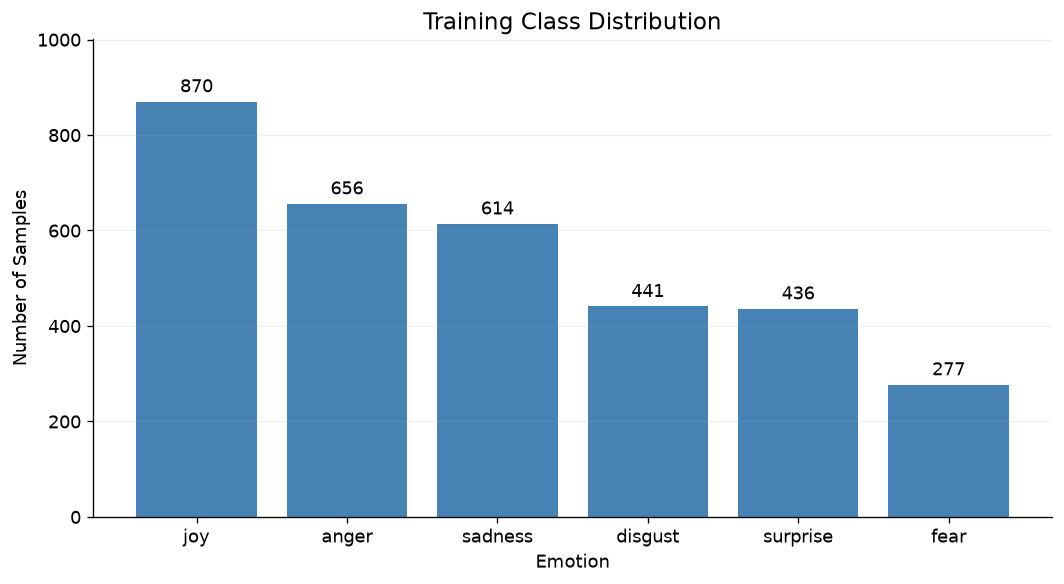

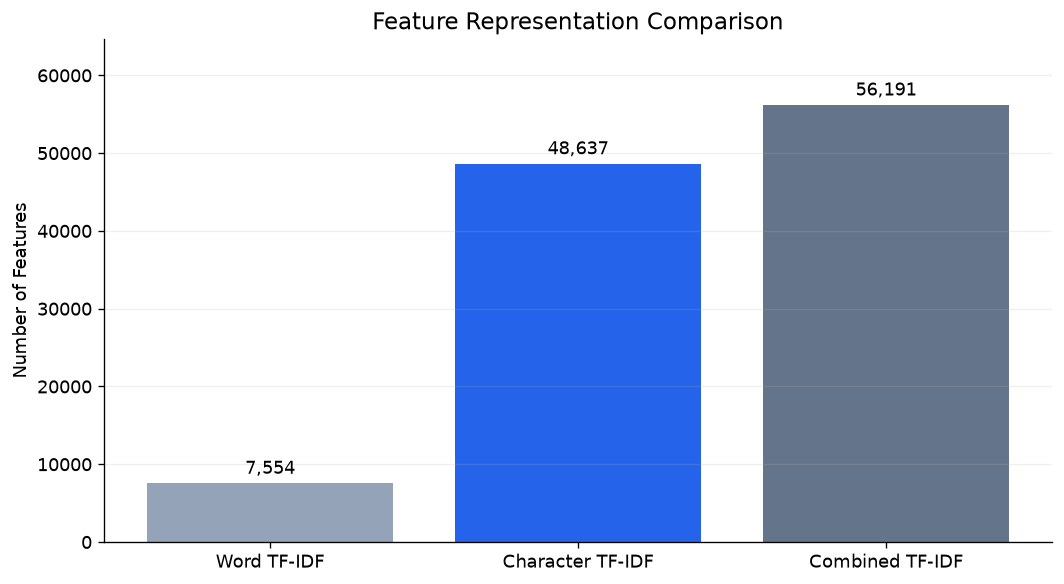

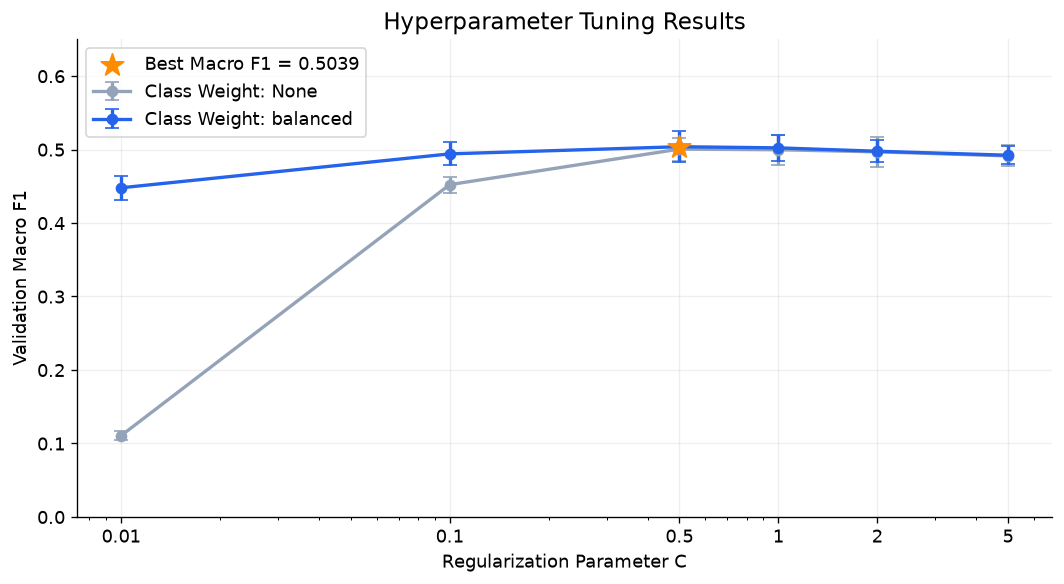

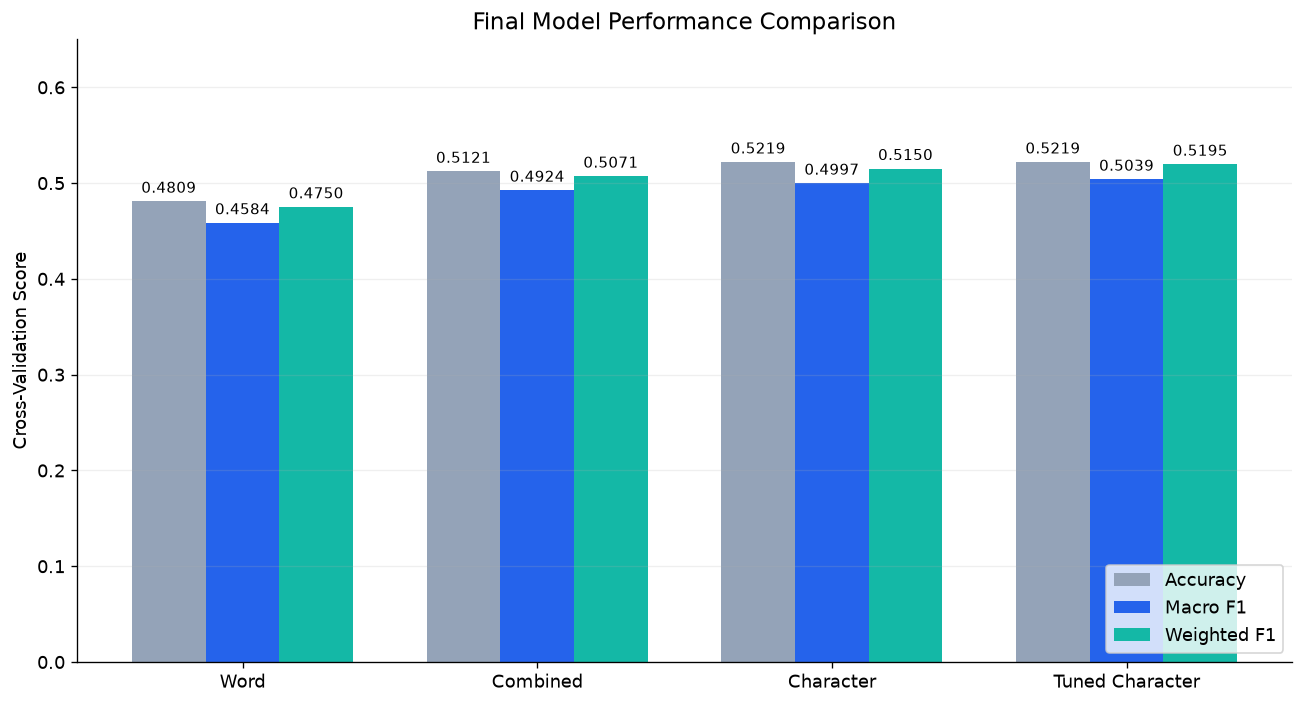

=== Generated Report Figures ===
[PASS] pics\homework_class_distribution.png (81,747 bytes)
[PASS] pics\homework_feature_comparison.png (82,016 bytes)
[PASS] pics\homework_hyperparameter_tuning.png (136,867 bytes)
[PASS] pics\homework_model_comparison.png (137,740 bytes)

All four report figures generated successfully.


In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Create the output directory
PICS_DIR = Path("pics")
PICS_DIR.mkdir(parents=True, exist_ok=True)

# Configure plot appearance
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# ==================================================
# Figure 1: Training Class Distribution
# ==================================================

class_counts = y_train.value_counts()

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color="steelblue"
)

ax.bar_label(bars, padding=3)

ax.set_title("Training Class Distribution")
ax.set_xlabel("Emotion")
ax.set_ylabel("Number of Samples")
ax.set_ylim(0, class_counts.max() * 1.15)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

fig.savefig(
    PICS_DIR / "homework_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# Figure 2: Feature Representation Comparison
# ==================================================

feature_labels = [
    "Word TF-IDF",
    "Character TF-IDF",
    "Combined TF-IDF"
]

feature_counts = [
    X_train_word.shape[1],
    X_train_char.shape[1],
    X_train_combined.shape[1]
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    feature_labels,
    feature_counts,
    color=["#94A3B8", "#2563EB", "#64748B"]
)

ax.bar_label(
    bars,
    labels=[f"{n:,}" for n in feature_counts],
    padding=3
)

ax.set_title("Feature Representation Comparison")
ax.set_ylabel("Number of Features")
ax.set_ylim(0, max(feature_counts) * 1.15)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

fig.savefig(
    PICS_DIR / "homework_feature_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# Figure 3: Hyperparameter Tuning Results
# ==================================================

cv_results = pd.DataFrame(grid_search.cv_results_)

plot_tuning = pd.DataFrame({
    "C": [
        p["classifier__C"]
        for p in cv_results["params"]
    ],
    "Class Weight": [
        str(p["classifier__class_weight"])
        for p in cv_results["params"]
    ],
    "Macro F1": cv_results["mean_test_macro_f1"],
    "Macro F1 SD": cv_results["std_test_macro_f1"]
})

fig, ax = plt.subplots(figsize=(9, 5))

for weight, color in [
    ("None", "#94A3B8"),
    ("balanced", "#2563EB")
]:

    subset = (
        plot_tuning[
            plot_tuning["Class Weight"] == weight
        ]
        .sort_values("C")
    )

    ax.errorbar(
        subset["C"],
        subset["Macro F1"],
        yerr=subset["Macro F1 SD"],
        marker="o",
        linewidth=2,
        capsize=4,
        color=color,
        label=f"Class Weight: {weight}"
    )

# Highlight the best configuration
best_c = grid_search.best_params_["classifier__C"]
best_f1 = grid_search.best_score_

ax.scatter(
    best_c,
    best_f1,
    color="darkorange",
    marker="*",
    s=200,
    zorder=5,
    label=f"Best Macro F1 = {best_f1:.4f}"
)

ax.set_xscale("log")
ax.set_xticks([0.01, 0.1, 0.5, 1, 2, 5])
ax.set_xticklabels(["0.01", "0.1", "0.5", "1", "2", "5"])

ax.set_title("Hyperparameter Tuning Results")
ax.set_xlabel("Regularization Parameter C")
ax.set_ylabel("Validation Macro F1")
ax.set_ylim(0, 0.65)
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    PICS_DIR / "homework_hyperparameter_tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# Figure 4: Final Model Performance
# ==================================================

plot_results = (
    pd.DataFrame(model_results)
    .drop_duplicates()
    .sort_values("Macro F1")
    .reset_index(drop=True)
)

short_names = {
    "Word TF-IDF + Linear SVM": "Word",
    "Combined TF-IDF + Linear SVM": "Combined",
    "Character TF-IDF + Linear SVM": "Character",
    "Tuned Character TF-IDF + Linear SVM": "Tuned Character"
}

plot_results["Short Name"] = (
    plot_results["Model"].map(short_names)
)

x = np.arange(len(plot_results))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width,
    plot_results["Accuracy"],
    width,
    label="Accuracy",
    color="#94A3B8"
)

bars2 = ax.bar(
    x,
    plot_results["Macro F1"],
    width,
    label="Macro F1",
    color="#2563EB"
)

bars3 = ax.bar(
    x + width,
    plot_results["Weighted F1"],
    width,
    label="Weighted F1",
    color="#14B8A6"
)

for bars in [bars1, bars2, bars3]:
    ax.bar_label(
        bars,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(plot_results["Short Name"])

ax.set_title("Final Model Performance Comparison")
ax.set_ylabel("Cross-Validation Score")
ax.set_ylim(0, 0.65)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

fig.savefig(
    PICS_DIR / "homework_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==================================================
# Verify generated figures
# ==================================================

expected_figures = [
    "homework_class_distribution.png",
    "homework_feature_comparison.png",
    "homework_hyperparameter_tuning.png",
    "homework_model_comparison.png"
]

print("=== Generated Report Figures ===")

for filename in expected_figures:

    path = PICS_DIR / filename

    assert path.exists()
    assert path.stat().st_size > 0

    print(f"[PASS] {path} ({path.stat().st_size:,} bytes)")

print("\nAll four report figures generated successfully.")